## Market Campaign Sales Prediction Project

### 1. Import the necessary Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 2. Import the Dataset

In [2]:
market_df = pd.read_csv(r'C:\Users\ADMIN\Desktop\Imarticus Learning\PGA 13\Machine Learning\Day 6 & 7\market_sales.csv')
market_df[:5]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
0,22483.0,17282.0,30.0,10516,Electronics,East,Budget,1000,2.11,96119
1,19308.0,18872.0,5.0,10413,Home Appliances,North,Budget,1000,2.15,82430
2,23238.0,13674.0,15.0,5715,Home Appliances,East,Mid-tier,1000,3.50,115771
3,27615.0,12551.0,20.0,10844,FMCG,South,Mid-tier,1825,2.14,83833
4,18829.0,10659.0,15.0,14564,Sports,East,Mid-tier,1000,2.55,103896


### 3. Exploratory Data Analysis

In [3]:
# shape
market_df.shape

(2500, 10)

In [4]:
# info
market_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   TV_Ad_Spend                    2405 non-null   float64
 1   Social_Media_Spend             2344 non-null   float64
 2   Discount_Offers                2318 non-null   float64
 3   Search_Engine_Marketing_Spend  2500 non-null   int64  
 4   Product_Category               2333 non-null   object 
 5   Region                         2373 non-null   object 
 6   Customer_Segment               2500 non-null   object 
 7   Website_Traffic                2500 non-null   int64  
 8   Conversion_Rate                2500 non-null   float64
 9   Sales                          2500 non-null   int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 195.4+ KB


In [5]:
# describe
market_df.describe()

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Sales
count,2405.000000,2344.000000,2318.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,20154.879834,14921.009812,14.309750,11900.040400,1175.940000,2.136004,83898.009200
std,4893.791754,4038.474895,8.885829,3577.258013,282.022437,0.645222,27916.528551
min,5000.000000,3000.000000,0.000000,2000.000000,1000.000000,0.500000,18747.000000
25%,16884.000000,12215.750000,10.000000,9479.750000,1000.000000,1.670000,63358.750000
50%,20126.000000,15007.500000,15.000000,11856.500000,1000.000000,2.090000,81320.500000
75%,23362.000000,17555.750000,20.000000,14394.250000,1279.000000,2.540000,101064.000000
max,39263.000000,30000.000000,30.000000,24351.000000,2542.000000,4.750000,221038.000000


In [6]:
# missing values
market_df.isna().sum()

TV_Ad_Spend                       95
Social_Media_Spend               156
Discount_Offers                  182
Search_Engine_Marketing_Spend      0
Product_Category                 167
Region                           127
Customer_Segment                   0
Website_Traffic                    0
Conversion_Rate                    0
Sales                              0
dtype: int64

In [7]:
market_df.isna().sum() / len(market_df) * 100

TV_Ad_Spend                      3.80
Social_Media_Spend               6.24
Discount_Offers                  7.28
Search_Engine_Marketing_Spend    0.00
Product_Category                 6.68
Region                           5.08
Customer_Segment                 0.00
Website_Traffic                  0.00
Conversion_Rate                  0.00
Sales                            0.00
dtype: float64

In [8]:
# Duplicates
market_df.duplicated().sum()

0

In [9]:
# Outliers

number_cols = market_df.select_dtypes(include='number').columns

for col in number_cols:
    Min = market_df[col].min()
    Q1 = market_df[col].quantile(0.25)
    Q2 = market_df[col].quantile(0.50)
    Mean = market_df[col].mean()
    Q3 = market_df[col].quantile(0.75)
    Max = market_df[col].max()
    IQR = Q3 - Q1
    
    lower_out_value = Q1 - 1.5* IQR
    upper_out_value = Q3 + 1.5*IQR
    
    Lower_Outliers = (market_df[col] < lower_out_value).sum()
    Upper_Outliers = (market_df[col] > upper_out_value).sum()
    total_outliers = Lower_Outliers + Upper_Outliers
    
    print(f'Column is {col}')
    print('-'*50)
    print(f'Minimum value of {col} is {Min}')
    print(f'Quartile 1 value of {col} is {Q1}')
    print(f'Median value of {col} is {Q2}')
    print(f'Average value of {col} is {Mean}')
    print(f'Quartile 3 value of {col} is {Q3}')
    print(f'Maximum Value of {col} is {Max}')
    print(f'Lower Outliers value of {col} is {lower_out_value}')
    print(f'Upper Outliers value of {col} is {upper_out_value}')
    print(f'Lower Outliers count is {Lower_Outliers}')
    print(f'Upper Outliers count is {Upper_Outliers}')
    print(f'Total Outliers Count is {total_outliers}')
    print('='*80)
    print(' ')

Column is TV_Ad_Spend
--------------------------------------------------
Minimum value of TV_Ad_Spend is 5000.0
Quartile 1 value of TV_Ad_Spend is 16884.0
Median value of TV_Ad_Spend is 20126.0
Average value of TV_Ad_Spend is 20154.879833679835
Quartile 3 value of TV_Ad_Spend is 23362.0
Maximum Value of TV_Ad_Spend is 39263.0
Lower Outliers value of TV_Ad_Spend is 7167.0
Upper Outliers value of TV_Ad_Spend is 33079.0
Lower Outliers count is 13
Upper Outliers count is 9
Total Outliers Count is 22
 
Column is Social_Media_Spend
--------------------------------------------------
Minimum value of Social_Media_Spend is 3000.0
Quartile 1 value of Social_Media_Spend is 12215.75
Median value of Social_Media_Spend is 15007.5
Average value of Social_Media_Spend is 14921.00981228669
Quartile 3 value of Social_Media_Spend is 17555.75
Maximum Value of Social_Media_Spend is 30000.0
Lower Outliers value of Social_Media_Spend is 4205.75
Upper Outliers value of Social_Media_Spend is 25565.75
Lower Outl

Column is TV_Ad_Spend
--------------------------------------------------
Minimum value of TV_Ad_Spend is 5000.0
Quartile 1 value of TV_Ad_Spend is 16884.0
Median value of TV_Ad_Spend is 20126.0
Average value of TV_Ad_Spend is 20154.879833679835
Quartile 3 value of TV_Ad_Spend is 23362.0
Maximum Value of TV_Ad_Spend is 39263.0
Lower Outliers value of TV_Ad_Spend is 7167.0
Upper Outliers value of TV_Ad_Spend is 33079.0
Lower Outliers count is 13
Upper Outliers count is 9
Total Outliers Count is 22
 


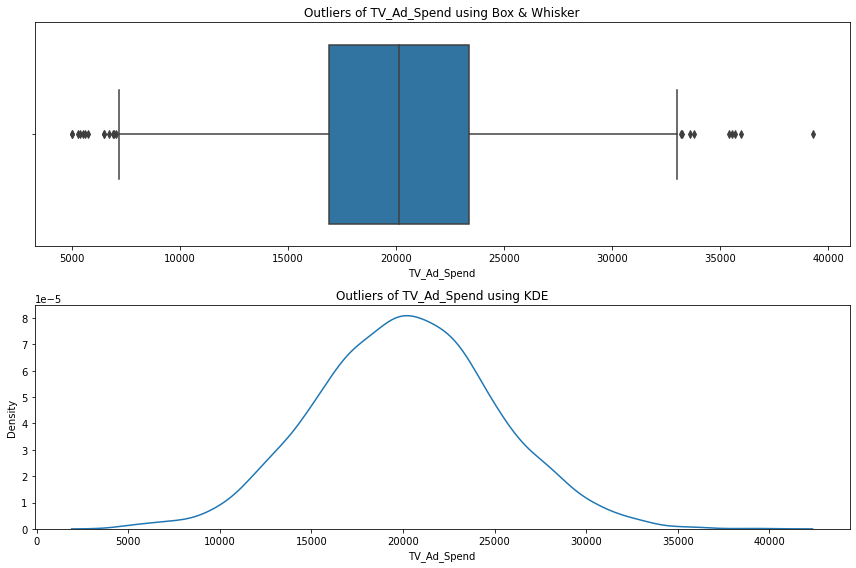

 
Column is Social_Media_Spend
--------------------------------------------------
Minimum value of Social_Media_Spend is 3000.0
Quartile 1 value of Social_Media_Spend is 12215.75
Median value of Social_Media_Spend is 15007.5
Average value of Social_Media_Spend is 14921.00981228669
Quartile 3 value of Social_Media_Spend is 17555.75
Maximum Value of Social_Media_Spend is 30000.0
Lower Outliers value of Social_Media_Spend is 4205.75
Upper Outliers value of Social_Media_Spend is 25565.75
Lower Outliers count is 13
Upper Outliers count is 11
Total Outliers Count is 24
 


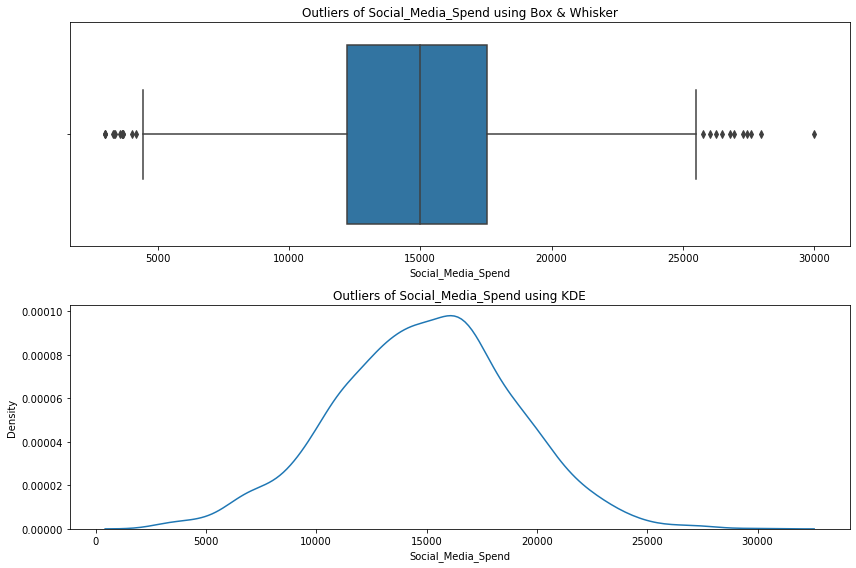

 
Column is Discount_Offers
--------------------------------------------------
Minimum value of Discount_Offers is 0.0
Quartile 1 value of Discount_Offers is 10.0
Median value of Discount_Offers is 15.0
Average value of Discount_Offers is 14.309749784296807
Quartile 3 value of Discount_Offers is 20.0
Maximum Value of Discount_Offers is 30.0
Lower Outliers value of Discount_Offers is -5.0
Upper Outliers value of Discount_Offers is 35.0
Lower Outliers count is 0
Upper Outliers count is 0
Total Outliers Count is 0
 


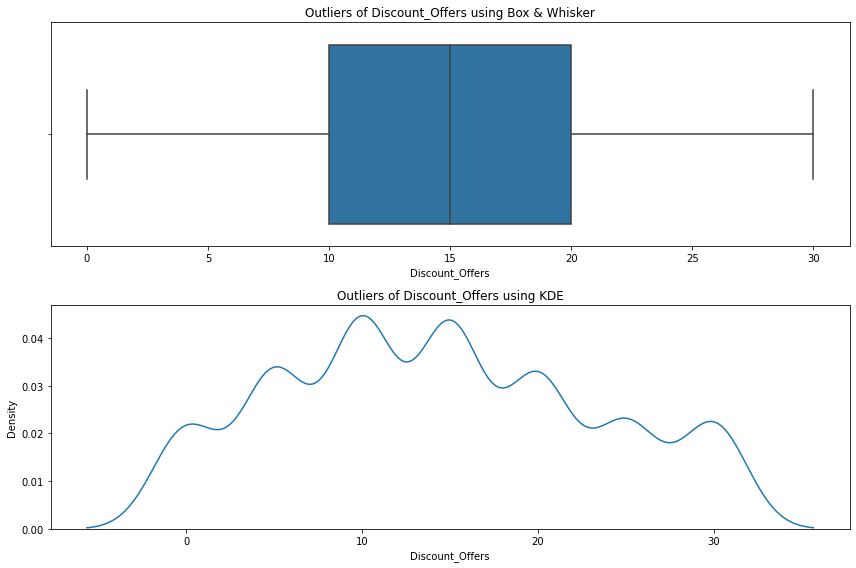

 
Column is Search_Engine_Marketing_Spend
--------------------------------------------------
Minimum value of Search_Engine_Marketing_Spend is 2000
Quartile 1 value of Search_Engine_Marketing_Spend is 9479.75
Median value of Search_Engine_Marketing_Spend is 11856.5
Average value of Search_Engine_Marketing_Spend is 11900.0404
Quartile 3 value of Search_Engine_Marketing_Spend is 14394.25
Maximum Value of Search_Engine_Marketing_Spend is 24351
Lower Outliers value of Search_Engine_Marketing_Spend is 2108.0
Upper Outliers value of Search_Engine_Marketing_Spend is 21766.0
Lower Outliers count is 5
Upper Outliers count is 10
Total Outliers Count is 15
 


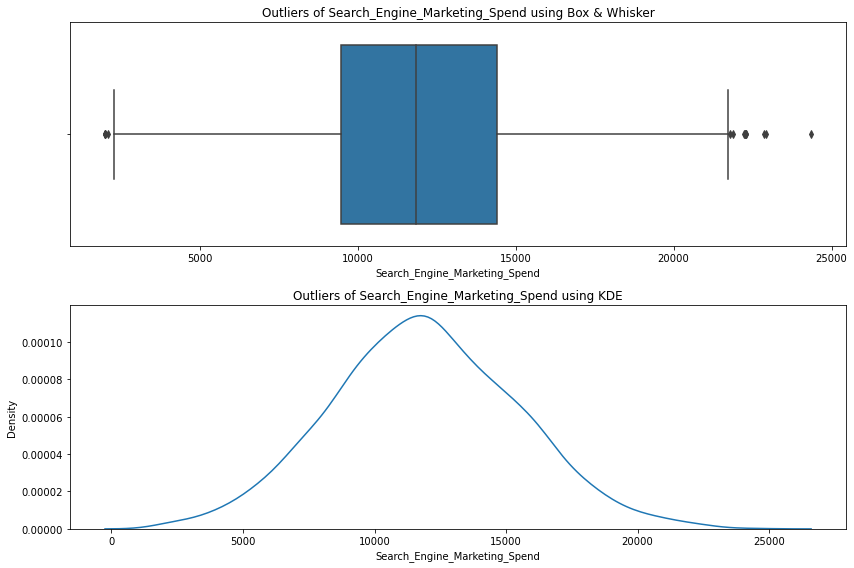

 
Column is Website_Traffic
--------------------------------------------------
Minimum value of Website_Traffic is 1000
Quartile 1 value of Website_Traffic is 1000.0
Median value of Website_Traffic is 1000.0
Average value of Website_Traffic is 1175.94
Quartile 3 value of Website_Traffic is 1279.0
Maximum Value of Website_Traffic is 2542
Lower Outliers value of Website_Traffic is 581.5
Upper Outliers value of Website_Traffic is 1697.5
Lower Outliers count is 0
Upper Outliers count is 191
Total Outliers Count is 191
 


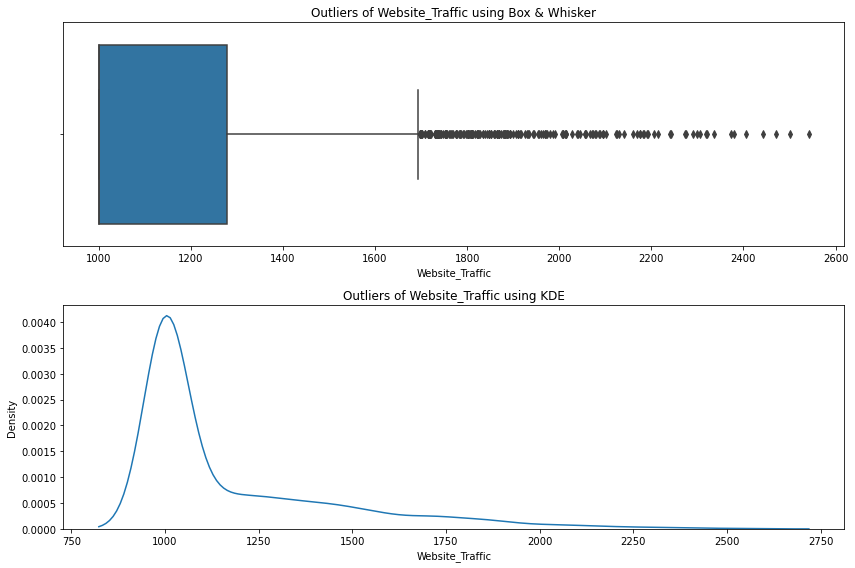

 
Column is Conversion_Rate
--------------------------------------------------
Minimum value of Conversion_Rate is 0.5
Quartile 1 value of Conversion_Rate is 1.67
Median value of Conversion_Rate is 2.09
Average value of Conversion_Rate is 2.1360040000000002
Quartile 3 value of Conversion_Rate is 2.54
Maximum Value of Conversion_Rate is 4.75
Lower Outliers value of Conversion_Rate is 0.36499999999999977
Upper Outliers value of Conversion_Rate is 3.845
Lower Outliers count is 0
Upper Outliers count is 23
Total Outliers Count is 23
 


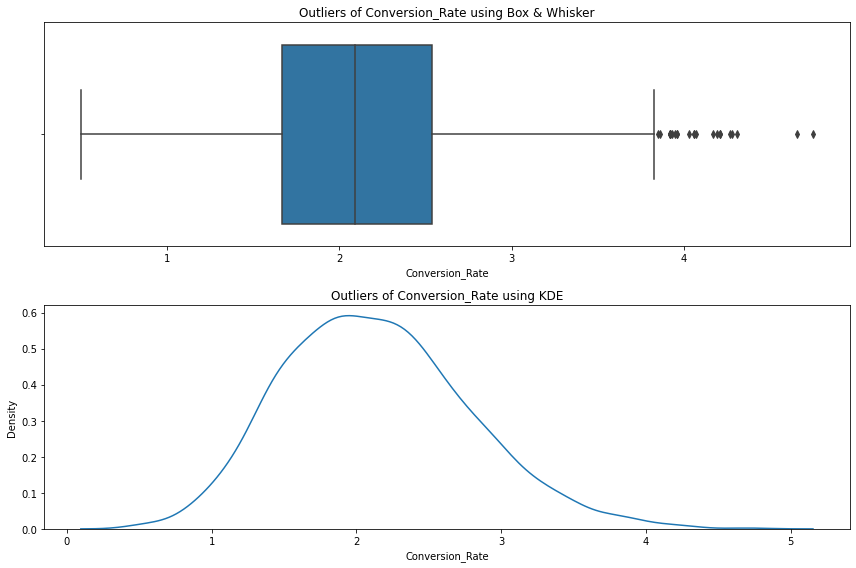

 
Column is Sales
--------------------------------------------------
Minimum value of Sales is 18747
Quartile 1 value of Sales is 63358.75
Median value of Sales is 81320.5
Average value of Sales is 83898.0092
Quartile 3 value of Sales is 101064.0
Maximum Value of Sales is 221038
Lower Outliers value of Sales is 6800.875
Upper Outliers value of Sales is 157621.875
Lower Outliers count is 0
Upper Outliers count is 33
Total Outliers Count is 33
 


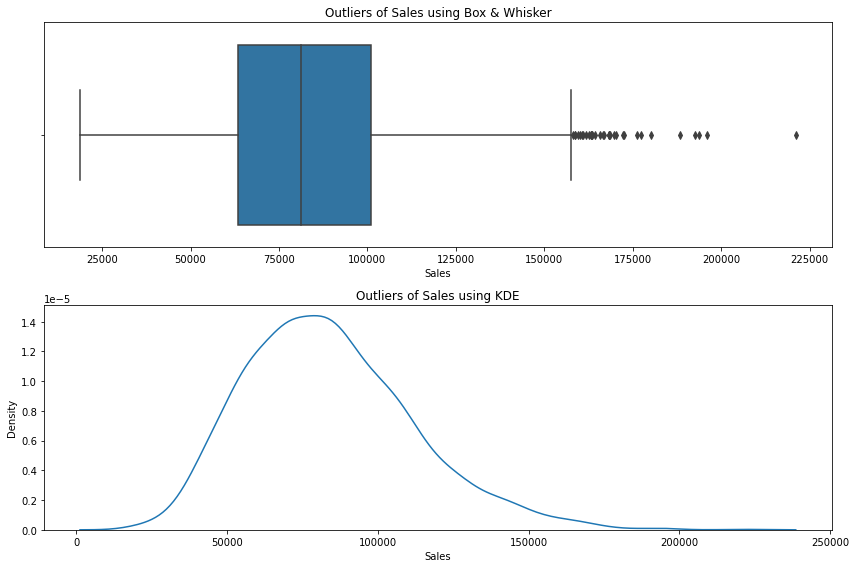

In [10]:
# Outliers

number_cols = market_df.select_dtypes(include='number').columns

for col in number_cols:
    Min = market_df[col].min()
    Q1 = market_df[col].quantile(0.25)
    Q2 = market_df[col].quantile(0.50)
    Mean = market_df[col].mean()
    Q3 = market_df[col].quantile(0.75)
    Max = market_df[col].max()
    IQR = Q3 - Q1
    
    lower_out_value = Q1 - 1.5* IQR
    upper_out_value = Q3 + 1.5*IQR
    
    Lower_Outliers = (market_df[col] < lower_out_value).sum()
    Upper_Outliers = (market_df[col] > upper_out_value).sum()
    total_outliers = Lower_Outliers + Upper_Outliers
    
    print(f'Column is {col}')
    print('-'*50)
    print(f'Minimum value of {col} is {Min}')
    print(f'Quartile 1 value of {col} is {Q1}')
    print(f'Median value of {col} is {Q2}')
    print(f'Average value of {col} is {Mean}')
    print(f'Quartile 3 value of {col} is {Q3}')
    print(f'Maximum Value of {col} is {Max}')
    print(f'Lower Outliers value of {col} is {lower_out_value}')
    print(f'Upper Outliers value of {col} is {upper_out_value}')
    print(f'Lower Outliers count is {Lower_Outliers}')
    print(f'Upper Outliers count is {Upper_Outliers}')
    print(f'Total Outliers Count is {total_outliers}')
    print(' ')
    
    # Visualize as well
    
    fig,axes = plt.subplots(2,1,figsize=(12,8))
    
    # Plot Box&Whisker
    sns.boxplot(market_df[col],ax=axes[0])
    axes[0].set_title(f'Outliers of {col} using Box & Whisker')
    
    # Plot KDE 
    sns.kdeplot(market_df[col],ax=axes[1])
    axes[1].set_title(f'Outliers of {col} using KDE')
    
    plt.tight_layout()
    plt.show()
    
    print('='*70)
    print(' ')

### 4. Split the Dataset

In [11]:
X = market_df.drop('Sales',axis=1)
y = market_df['Sales']

print(X.shape)
print(y.shape)

(2500, 9)
(2500,)


In [12]:
# Split into train and Test

from sklearn.model_selection import train_test_split as tts

X_train,X_test,y_train,y_test = tts(X,y,test_size=0.2,random_state=42)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(2000, 9)
(2000,)
(500, 9)
(500,)


### 5.Transformations

In [13]:
## a. Missing values

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(include='object').columns

In [14]:
num_cols

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Discount_Offers',
       'Search_Engine_Marketing_Spend', 'Website_Traffic', 'Conversion_Rate'],
      dtype='object')

In [15]:
cat_cols

Index(['Product_Category', 'Region', 'Customer_Segment'], dtype='object')

In [16]:
## Transforming with Median value for Numerical columns of Train datset

#for col in num_cols:
    #X_train[col] = X_train[col].fillna(X_train[col].median())

In [17]:
## Transforming with Median value for Numerical columns of Train datset

for col in num_cols:
    X_train[col].fillna(X_train[col].median(),inplace=True)

In [18]:
## Transforming with Median value for Numerical columns of Test datset

for col in num_cols:
    X_test[col].fillna(X_train[col].median(),inplace=True)

In [19]:
## Transforming with Mode value for Categorical columns of Train datset

for col in cat_cols:
    X_train[col].fillna(X_train[col].mode()[0],inplace=True)

In [20]:
## Transforming with Mode value for Categorical columns of Test datset

for col in cat_cols:
    X_test[col].fillna(X_train[col].mode()[0],inplace=True)

In [21]:
X_train.isna().sum()

TV_Ad_Spend                      0
Social_Media_Spend               0
Discount_Offers                  0
Search_Engine_Marketing_Spend    0
Product_Category                 0
Region                           0
Customer_Segment                 0
Website_Traffic                  0
Conversion_Rate                  0
dtype: int64

In [22]:
X_test.isna().sum()

TV_Ad_Spend                      0
Social_Media_Spend               0
Discount_Offers                  0
Search_Engine_Marketing_Spend    0
Product_Category                 0
Region                           0
Customer_Segment                 0
Website_Traffic                  0
Conversion_Rate                  0
dtype: int64

#### b. Outliers/Skewness Treatment

In [23]:
for col in num_cols:
    print(f'Skewness value of {col} is {X_train[col].skew()}')

Skewness value of TV_Ad_Spend is 0.04405797211560788
Skewness value of Social_Media_Spend is -0.06368656920945912
Skewness value of Discount_Offers is 0.13613613143701309
Skewness value of Search_Engine_Marketing_Spend is 0.13408013168045632
Skewness value of Website_Traffic is 1.8513189578181586
Skewness value of Conversion_Rate is 0.4106301617267023


In [24]:
for col in num_cols:
    print(f'Skewness value of {col} is {np.log1p(X_train[col].skew())}')

Skewness value of TV_Ad_Spend is 0.04311501676514536
Skewness value of Social_Media_Spend is -0.06580499660259045
Skewness value of Discount_Offers is 0.1276331471308932
Skewness value of Search_Engine_Marketing_Spend is 0.12582186566660347
Skewness value of Website_Traffic is 1.0477816794421673
Skewness value of Conversion_Rate is 0.3440365277600723


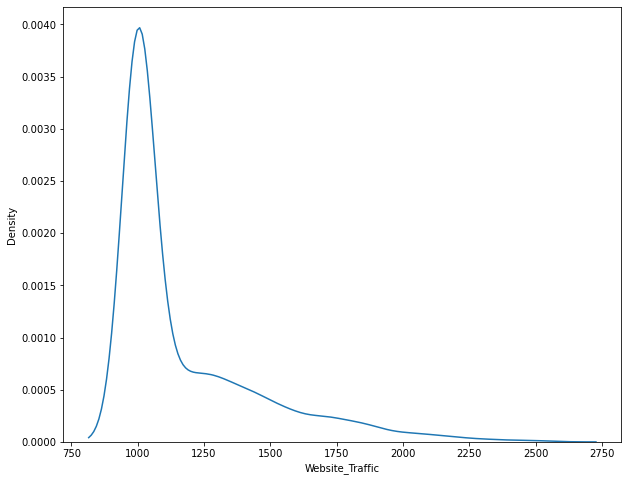

In [25]:
plt.figure(figsize=(10,8))

sns.kdeplot(X_train['Website_Traffic'])
plt.show()

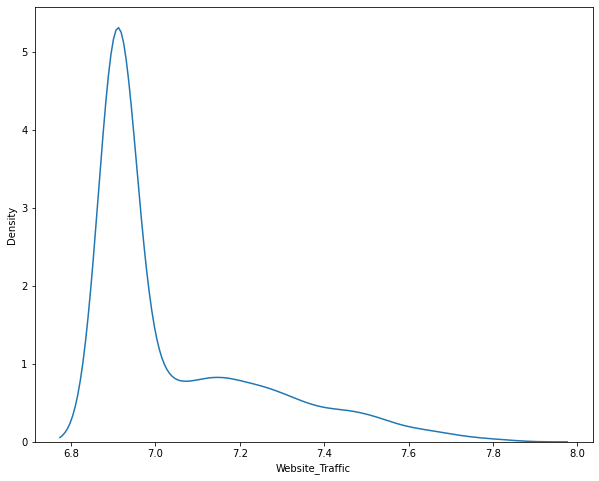

In [26]:
plt.figure(figsize=(10,8))

sns.kdeplot(np.log1p(X_train['Website_Traffic']))
plt.show()

In [27]:
from sklearn.preprocessing import PowerTransformer

In [28]:
pt = PowerTransformer(method='box-cox')
pt

PowerTransformer(method='box-cox')

In [29]:
pt.fit_transform(X_train[['Website_Traffic']])

array([[0.00000000e+00],
       [1.11022302e-16],
       [1.11022302e-16],
       ...,
       [1.11022302e-16],
       [0.00000000e+00],
       [0.00000000e+00]])

In [30]:
pt.fit_transform(X_train[['Website_Traffic']]).min()# box-cox

0.0

In [31]:
pt.fit_transform(X_train[['Website_Traffic']]).max()

1.1102230246251565e-16

In [32]:
pt1 = PowerTransformer()
pt1

PowerTransformer()

In [33]:
pt1.fit_transform(X_train[['Website_Traffic']])

array([[-5.55111512e-17],
       [ 1.66533454e-16],
       [ 1.38777878e-16],
       ...,
       [ 1.38777878e-16],
       [-5.55111512e-17],
       [-5.55111512e-17]])

In [34]:
pt1.fit_transform(X_train[['Website_Traffic']]).min()

-5.551115123125783e-17

In [35]:
pt1.fit_transform(X_train[['Website_Traffic']]).max()

1.6653345369377348e-16

In [36]:
## IQR method for Outliers Treatment for trainig datset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    total_outliers = ((X_train[col] <lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 23
Total Outliers count in Social_Media_Spend is 34
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 11
Total Outliers count in Website_Traffic is 150
Total Outliers count in Conversion_Rate is 16


In [37]:
## IQR method for Outliers Treatment for Testing dataset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    total_outliers = ((X_test[col] <lower_out_value) | (X_test[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 10
Total Outliers count in Social_Media_Spend is 6
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 3
Total Outliers count in Website_Traffic is 41
Total Outliers count in Conversion_Rate is 5


In [38]:
## Treatment


for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    total_outliers = ((X_train[col] <lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    if total_outliers>0:
        X_train[col] = X_train[col].clip(lower_out_value,upper_out_value)
        X_test[col] = X_test[col].clip(lower_out_value,upper_out_value)

In [39]:
## IQR method for Outliers Treatment for trainig datset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    total_outliers = ((X_train[col] <lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 0
Total Outliers count in Social_Media_Spend is 0
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 0
Total Outliers count in Website_Traffic is 0
Total Outliers count in Conversion_Rate is 0


In [40]:
## IQR method for Outliers Treatment for Testing dataset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR
    
    total_outliers = ((X_test[col] <lower_out_value) | (X_test[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 0
Total Outliers count in Social_Media_Spend is 0
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 0
Total Outliers count in Website_Traffic is 0
Total Outliers count in Conversion_Rate is 0


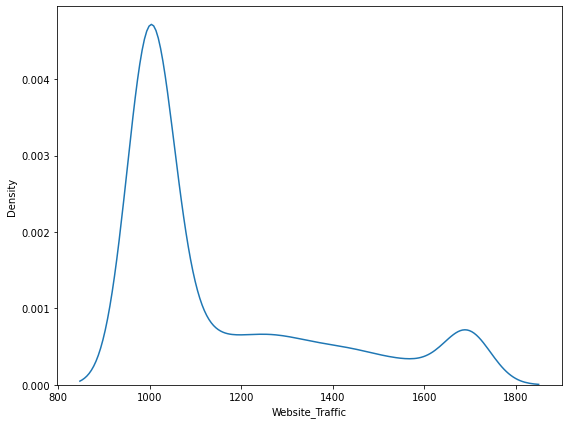

In [41]:
plt.figure(figsize=(8,6))

sns.kdeplot(X_train['Website_Traffic'])

plt.tight_layout()
plt.show()

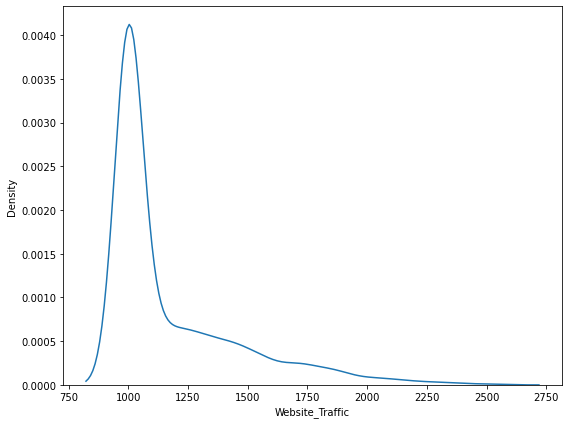

In [42]:
plt.figure(figsize=(8,6))

sns.kdeplot(market_df['Website_Traffic'])

plt.tight_layout()
plt.show()

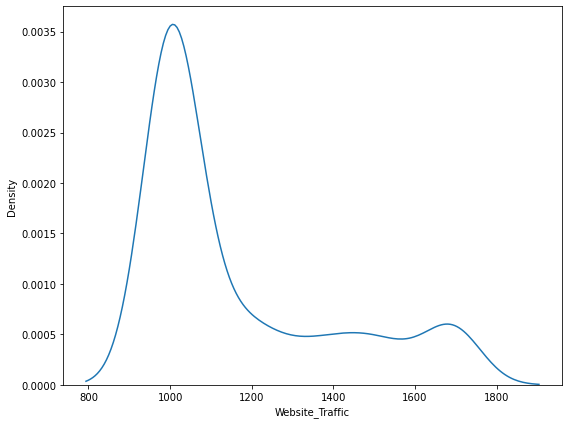

In [43]:
plt.figure(figsize=(8,6))

sns.kdeplot(X_test['Website_Traffic'])

plt.tight_layout()
plt.show()

In [44]:
X_train['Website_Traffic'].skew()

1.268857424638329

In [45]:
X_train.shape

(2000, 9)

### Concat the training dataset for Visulization and Statistical test

In [46]:
train_df = pd.concat([X_train,y_train],axis=1)
train_df[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
2055,15903.0,13798.0,20.0,5958.0,Sports,North,Mid-tier,1000.0,1.14,42281
1961,21427.0,22397.0,25.0,12812.0,Home Appliances,East,Mid-tier,1549.0,3.06,142404
1864,26521.0,12613.0,20.0,11959.0,FMCG,North,Budget,1474.0,2.09,86869


In [47]:
train_df.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                  float64
Search_Engine_Marketing_Spend    float64
Product_Category                  object
Region                            object
Customer_Segment                  object
Website_Traffic                  float64
Conversion_Rate                  float64
Sales                              int64
dtype: object

In [48]:
train_df['Discount_Offers'] = train_df['Discount_Offers'].astype('object')

In [49]:
train_df.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                   object
Search_Engine_Marketing_Spend    float64
Product_Category                  object
Region                            object
Customer_Segment                  object
Website_Traffic                  float64
Conversion_Rate                  float64
Sales                              int64
dtype: object

### Analyze Numerical columns w.r.t to Sales

In [50]:
num_cols1 = train_df.select_dtypes(include='number').columns
cat_cols1 = train_df.select_dtypes(include='object').columns

In [51]:
num_cols1

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Search_Engine_Marketing_Spend',
       'Website_Traffic', 'Conversion_Rate', 'Sales'],
      dtype='object')

In [52]:
cat_cols1

Index(['Discount_Offers', 'Product_Category', 'Region', 'Customer_Segment'], dtype='object')

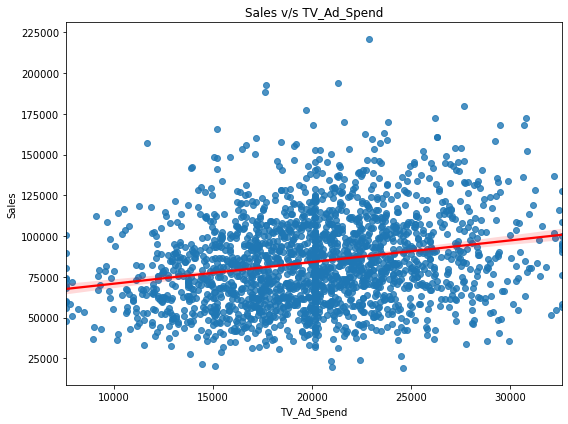

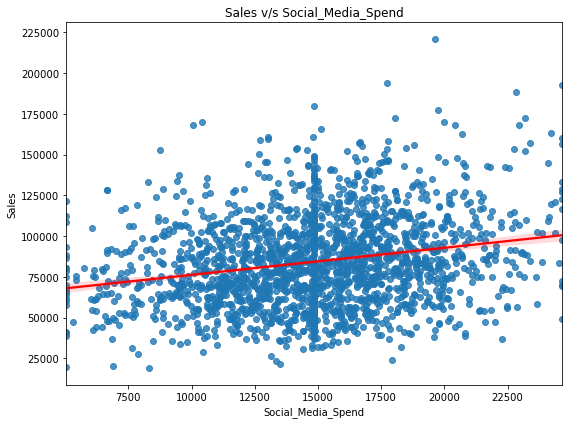

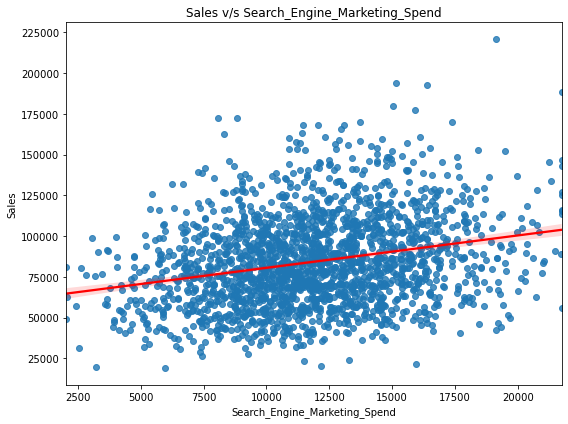

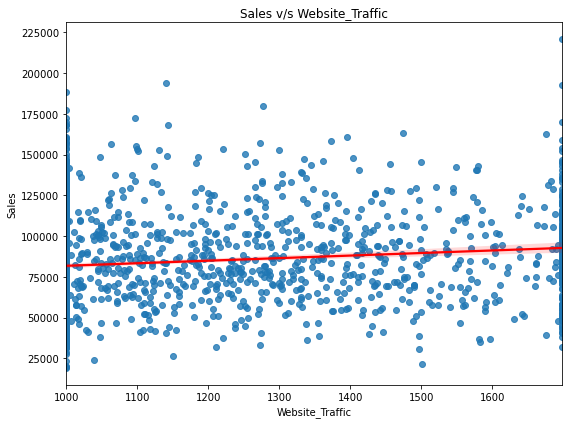

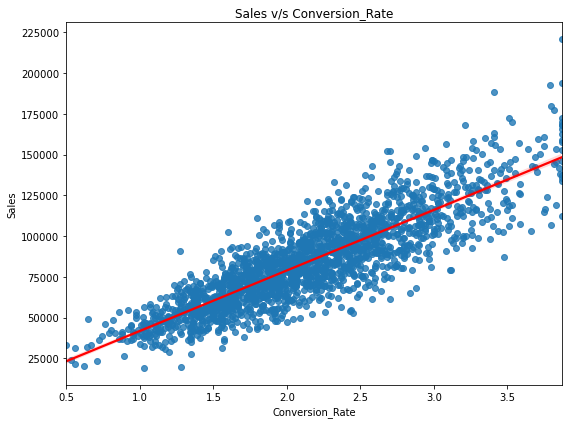

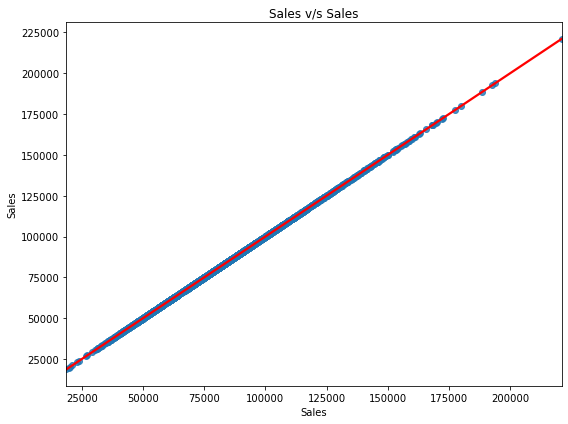

In [53]:
for col in num_cols1:
    plt.figure(figsize=(8,6))
    
    sns.regplot(data=train_df,x=col,y='Sales',line_kws={'color' : 'red'})
    
    plt.title(f'Sales v/s {col}')
    
    plt.tight_layout()
    plt.show()

### Insights:
#### Sales and Conversion rate are highly correlated

### Analyze Categorical columns and Sales

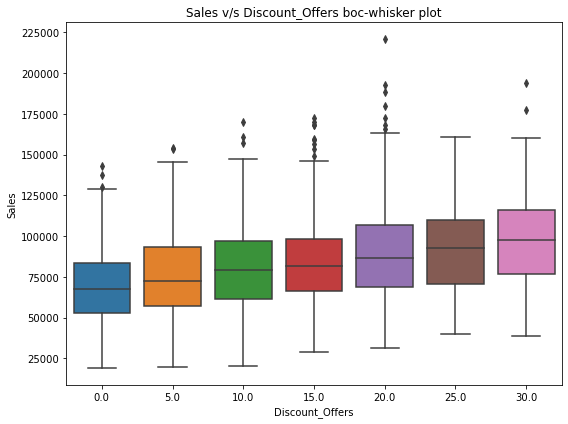

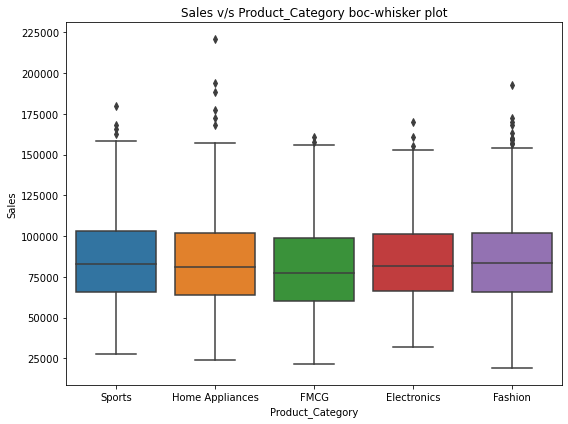

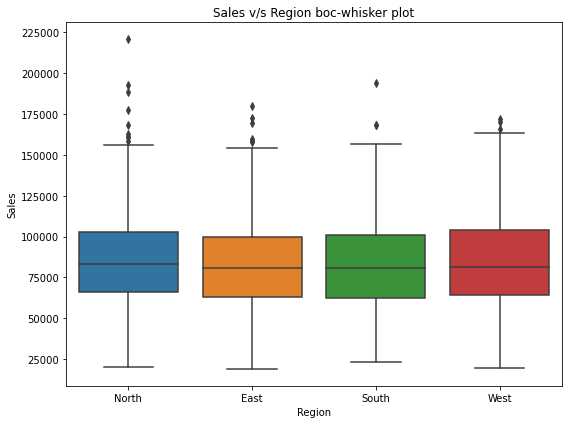

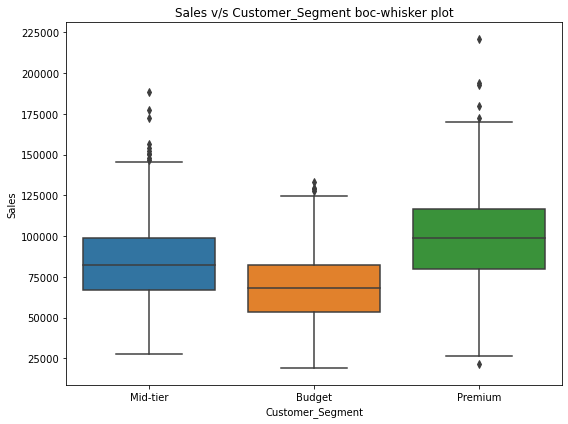

In [54]:
for col in cat_cols1:
    plt.figure(figsize=(8,6))
    
    sns.boxplot(data=train_df,x=col,y='Sales')
    
    plt.title(f'Sales v/s {col} boc-whisker plot')
    
    plt.tight_layout()
    plt.show()

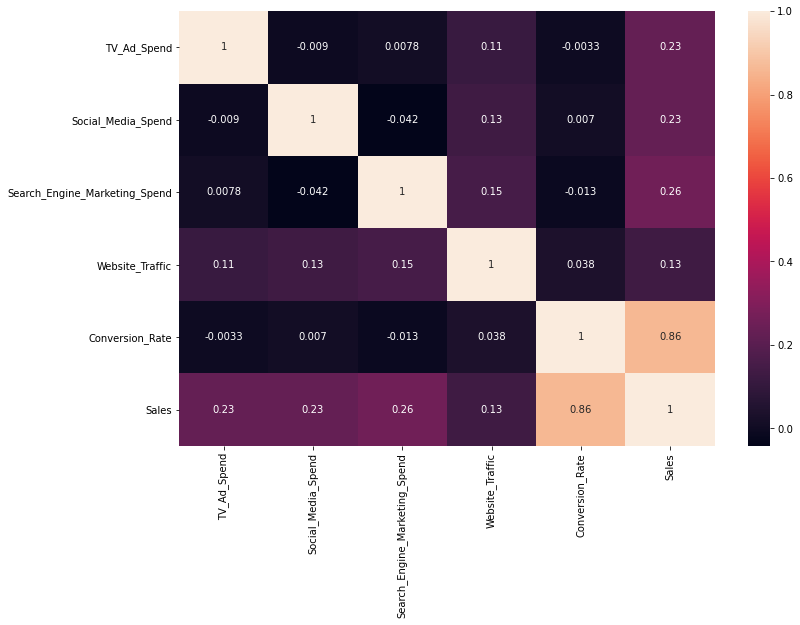

In [55]:
### Heatmap


plt.figure(figsize=(12,8))
corr_matrix = train_df.corr()
sns.heatmap(corr_matrix,annot=True)

plt.show()

### Statistical Test

In [56]:
from scipy.stats import f_oneway

In [57]:
train_df.groupby(['Region'])

In [58]:
train_df.groupby(['Region']).groups

{'East': [1961, 461, 266, 1560, 416, 472, 2419, 808, 2491, 278, 1517, 1234, 1532, 1501, 219, 618, 1247, 303, 1738, 2376, 879, 1005, 1033, 192, 1378, 1904, 700, 340, 1286, 1263, 786, 1303, 761, 1525, 2086, 281, 727, 1351, 555, 1913, 2113, 283, 360, 2003, 1094, 423, 2347, 1587, 1710, 1559, 1569, 374, 1667, 1054, 636, 185, 1804, 1656, 1778, 2405, 607, 1557, 1135, 23, 2387, 1717, 311, 351, 1744, 962, 1389, 990, 1590, 836, 2417, 2499, 2358, 1877, 2240, 263, 105, 121, 821, 1488, 2306, 941, 1647, 552, 690, 1691, 2216, 343, 1374, 500, 677, 272, 733, 377, 561, 590, ...], 'North': [2055, 1864, 2326, 530, 290, 798, 930, 1564, 2008, 2158, 1869, 765, 426, 2389, 1989, 2285, 961, 1639, 489, 1553, 2464, 366, 1410, 2280, 120, 1127, 1808, 840, 1575, 889, 729, 736, 1073, 759, 297, 1237, 529, 1933, 1612, 944, 511, 800, 1394, 874, 2275, 1110, 2449, 548, 306, 694, 781, 1376, 1435, 13, 514, 409, 861, 2159, 415, 304, 427, 2044, 1552, 2290, 744, 2333, 911, 309, 1987, 2366, 87, 1550, 273, 1242, 63, 1380, 1672, 

In [59]:
for name,groups in train_df.groupby(['Region']):
    print(name)
    print('-'*50)
    print(groups)

East
--------------------------------------------------
      TV_Ad_Spend  Social_Media_Spend Discount_Offers  \
1961      21427.0           22397.000            25.0   
461       20176.0           12565.000             5.0   
266       28162.0           14865.000            25.0   
1560      19893.0           17999.000            15.0   
416       27755.0           14297.000            15.0   
...           ...                 ...             ...   
1482      20137.0           24639.625            20.0   
330       19938.0            8184.000            15.0   
466       23070.0           16410.000            15.0   
1095      19596.0           19585.000            10.0   
1294      20409.0           15031.000            25.0   

      Search_Engine_Marketing_Spend Product_Category Region Customer_Segment  \
1961                        12812.0  Home Appliances   East         Mid-tier   
461                         14308.0      Electronics   East          Premium   
266                

In [60]:
for name,groups in train_df.groupby(['Region']):
    print(name)
    print('-'*50)
    print(groups['Sales'])

East
--------------------------------------------------
1961    142404
461      85361
266      48498
1560     79679
416      83349
         ...  
1482    122854
330      91517
466     131122
1095     38059
1294     94051
Name: Sales, Length: 598, dtype: int64
North
--------------------------------------------------
2055     42281
1864     86869
2326     74297
530      65365
290      89237
         ...  
2047     54344
747      81058
21      129169
2391     64677
1238    118503
Name: Sales, Length: 463, dtype: int64
South
--------------------------------------------------
109     112549
1962     72513
354      85972
1545     95151
2446     85095
         ...  
474     110845
1515     63675
1685     82315
1130     88621
860     115783
Name: Sales, Length: 462, dtype: int64
West
--------------------------------------------------
605     133340
931      87760
2279     57437
1014    122541
2401    107585
         ...  
2433    107154
769     116969
2135     67175
2169    111144
1638     819

In [61]:
for col in cat_cols1:
   
    groups = [group['Sales'].values for name, group in train_df.groupby(col)]
    
    
    f_stat, p_val = f_oneway(*groups)
    
    status = "Average Sales are not same " if p_val < 0.05 else "Average Sales are same"
    print(f"Feature '{col}': F-Statistic = {f_stat:.2f}, P-Value = {p_val:.4e} -> {status}")

Feature 'Discount_Offers': F-Statistic = 28.27, P-Value = 1.4048e-32 -> Average Sales are not same 
Feature 'Product_Category': F-Statistic = 1.55, P-Value = 1.8409e-01 -> Average Sales are same
Feature 'Region': F-Statistic = 2.01, P-Value = 1.0989e-01 -> Average Sales are same
Feature 'Customer_Segment': F-Statistic = 260.34, P-Value = 3.3748e-101 -> Average Sales are not same 


###  Apply Encoding techniques to convert Categorical column values to Numerical values

In [62]:
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

In [63]:
X_train_encoded.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                  float64
Search_Engine_Marketing_Spend    float64
Product_Category                  object
Region                            object
Customer_Segment                  object
Website_Traffic                  float64
Conversion_Rate                  float64
dtype: object

In [64]:
cat_cols2 = X_train_encoded.select_dtypes(include='object').columns
num_cols2 = X_train_encoded.select_dtypes(include='float64').columns

In [65]:
cat_cols2

Index(['Product_Category', 'Region', 'Customer_Segment'], dtype='object')

In [66]:
X_train_encoded = pd.get_dummies(X_train_encoded,drop_first=True,dtype='int')

In [67]:
X_test_encoded = pd.get_dummies(X_test_encoded,drop_first=True,dtype='int')

In [68]:
X_train_encoded[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Product_Category_FMCG,Product_Category_Fashion,Product_Category_Home Appliances,Product_Category_Sports,Region_North,Region_South,Region_West,Customer_Segment_Mid-tier,Customer_Segment_Premium
2055,15903.0,13798.0,20.0,5958.0,1000.0,1.14,0,0,0,1,1,0,0,1,0
1961,21427.0,22397.0,25.0,12812.0,1549.0,3.06,0,0,1,0,0,0,0,1,0
1864,26521.0,12613.0,20.0,11959.0,1474.0,2.09,1,0,0,0,1,0,0,0,0


In [69]:
X_test_encoded[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Product_Category_FMCG,Product_Category_Fashion,Product_Category_Home Appliances,Product_Category_Sports,Region_North,Region_South,Region_West,Customer_Segment_Mid-tier,Customer_Segment_Premium
1447,22931.0,16712.0,20.0,10385.0,1000.0,3.06,0,0,0,1,0,1,0,1,0
1114,20752.0,17771.0,5.0,11275.0,1537.0,2.35,0,0,1,0,0,0,1,1,0
1064,18187.0,18833.0,0.0,12630.0,1090.0,1.38,0,0,0,1,0,0,0,0,0


In [70]:
X_train['Product_Category'].unique()

array(['Sports', 'Home Appliances', 'FMCG', 'Electronics', 'Fashion'],
      dtype=object)

### Scaling Transformation on Numerical columns

In [71]:
from sklearn.preprocessing import StandardScaler

In [72]:
ss = StandardScaler()
ss

StandardScaler()

In [73]:
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

In [74]:
ss.fit_transform(X_train_scaled[num_cols2])

array([[-0.89098189, -0.27177992,  0.6449532 , -1.6634716 , -0.67687864,
        -1.56907265],
       [ 0.27058939,  1.96519653,  1.23341415,  0.26496149,  1.67704935,
         1.43268049],
       [ 1.34174147, -0.58005032,  0.6449532 ,  0.02496245,  1.35547449,
        -0.08383021],
       ...,
       [ 0.30822901,  0.66135585, -1.12042965,  0.33361303,  1.07248861,
         0.10377936],
       [ 0.05652719,  0.04897737,  1.23341415, -1.1364866 , -0.67687864,
         0.65097394],
       [ 0.1837449 , -1.15939054, -1.12042965,  1.26069022, -0.67687864,
         1.10436374]])

In [75]:
X_train_scaled[num_cols2] = ss.fit_transform(X_train_scaled[num_cols2])

X_test_scaled[num_cols2] = ss.transform(X_test_scaled[num_cols2])

In [76]:
X_train_scaled.shape

(2000, 15)

In [77]:
X_test_scaled.shape

(500, 15)

###  Check Assumptions of Linear Regression

Linear regression works best when four things hold. We check each one.

| Assumption | Plain-English meaning | Check |
|---|---|---|
| Linearity | Features relate to Sales in a straight-line way | Scatter plots with a line |
| No multicollinearity | Features are not copies of each other | VIF |
| Normal residuals | Prediction errors are roughly bell-shaped | Q-Q plot + Shapiro-Wilk |
| Homoscedasticity | Errors have a similar spread everywhere | Residuals vs Fitted plot |
| Independency | Errors should be Independent  | ACF/PACF & Durbin-Watson Test |

In [78]:
num_cols1

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Search_Engine_Marketing_Spend',
       'Website_Traffic', 'Conversion_Rate', 'Sales'],
      dtype='object')

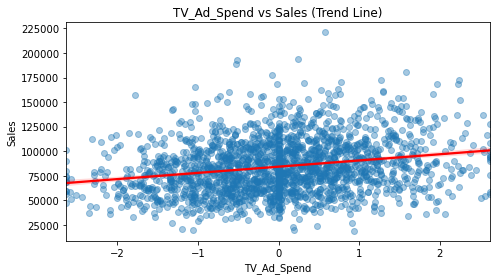

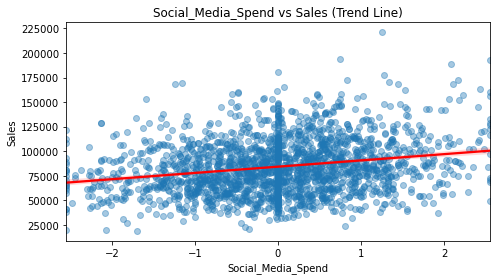

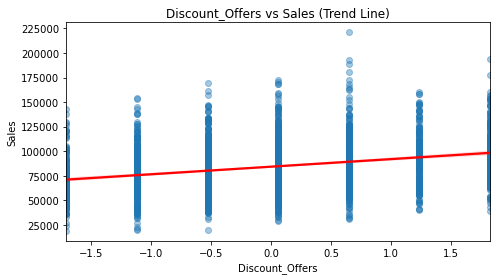

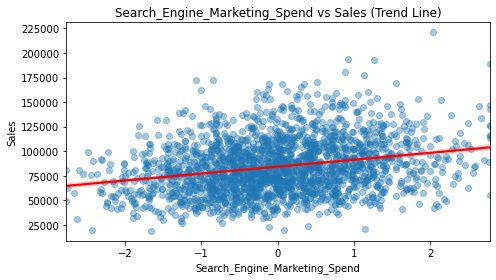

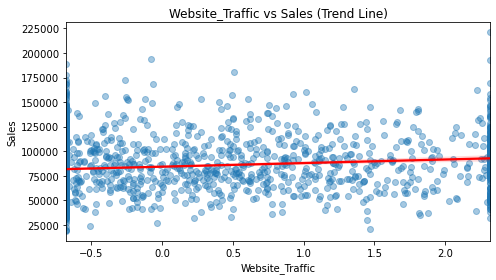

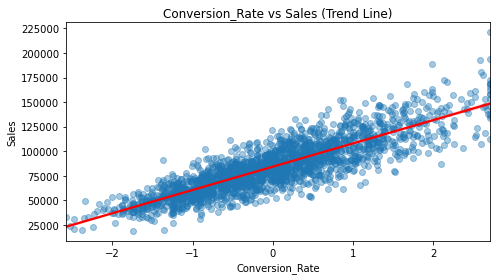

In [79]:
### a. Linear Relationship between X and y

for col in num_cols2:
    plt.figure(figsize=(7, 4))
   
    sns.regplot(data=X_train_scaled, x=col, y=y_train, scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
    plt.title(f'{col} vs Sales (Trend Line)')
    plt.tight_layout()
    plt.show()

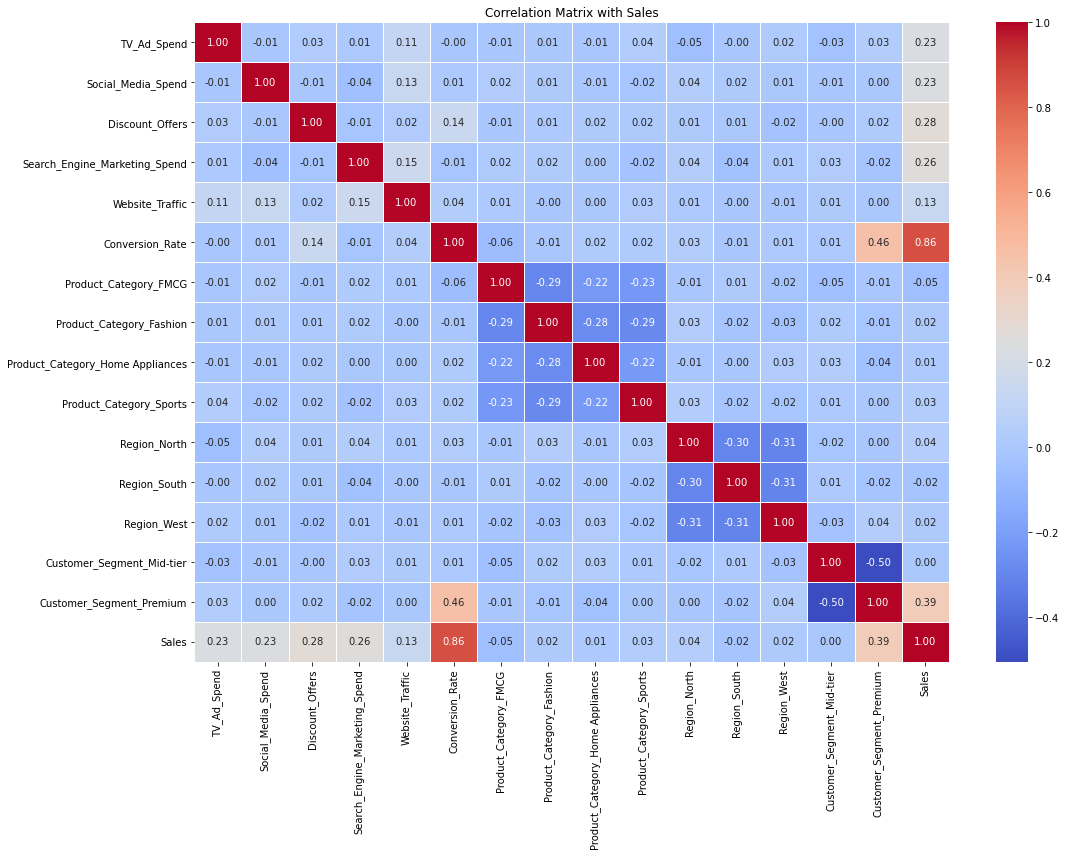

In [82]:
plt.figure(figsize=(16,12))

corr_matrix = pd.concat([X_train_scaled, y_train], axis=1).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix with Sales')
plt.tight_layout()
plt.show()

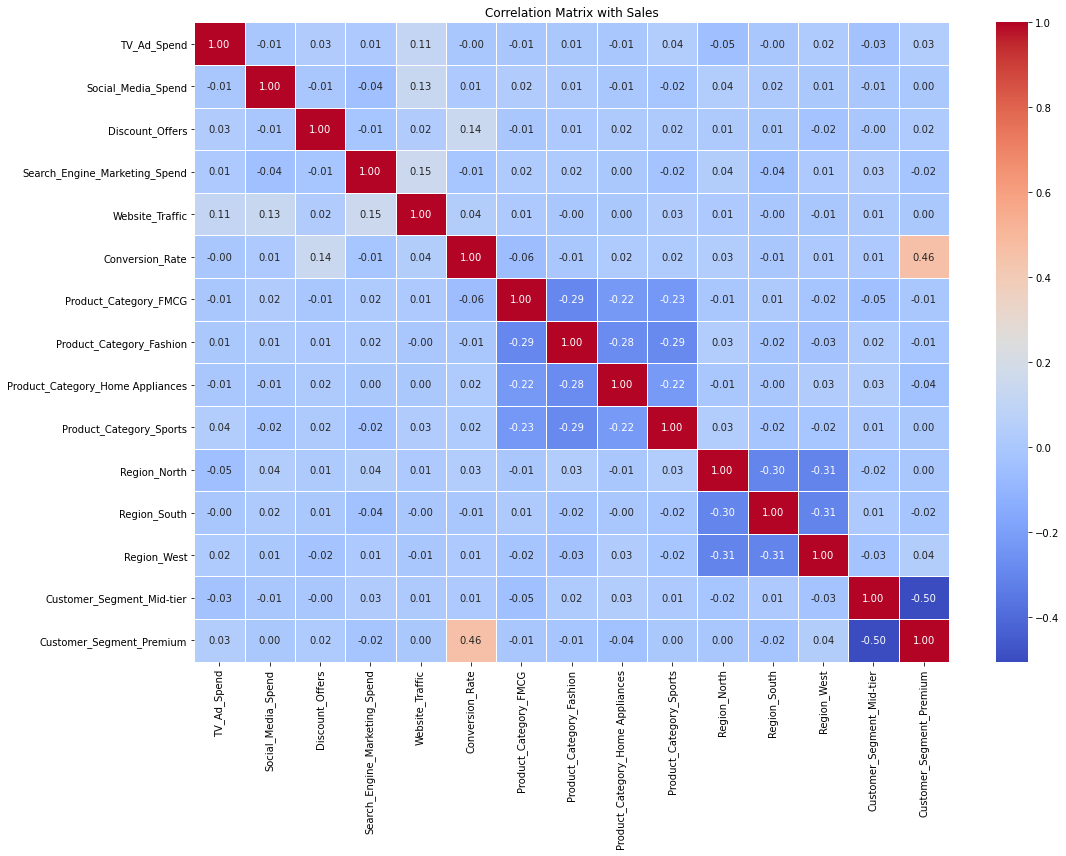

In [84]:
## b. No Multicolinarity

plt.figure(figsize=(16,12))
# Calculate correlation matrix only on numerical fields
corr_matrix = X_train_scaled.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix with Sales')
plt.tight_layout()
plt.show()

In [85]:
## b. No Multicolinarity

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

X_vif = sm.add_constant(X_train_scaled)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns
vif_data['VIF Scores'] = [
    vif(X_vif.values,i) for i in range(X_vif.shape[1])
]

vif_data

,Feature,VIF Scores
0,const,11.050084
1,TV_Ad_Spend,1.021568
2,Social_Media_Spend,1.027128
3,Discount_Offers,1.029836
4,Search_Engine_Marketing_Spend,1.033990
5,Website_Traffic,1.063031
6,Conversion_Rate,1.449355
7,Product_Category_FMCG,1.680915
8,Product_Category_Fashion,1.829829
9,Product_Category_Home Appliances,1.634531


In [89]:
X_vif1 = sm.add_constant(X_train_scaled.drop(['Customer_Segment_Premium'],axis=1))

vif_data1 = pd.DataFrame()

vif_data1['Feature'] = X_vif1.columns
vif_data1['VIF Scores'] = [
    vif(X_vif1.values,i) for i in range(X_vif1.shape[1])
]

vif_data1

,Feature,VIF Scores
0,const,8.533126
1,TV_Ad_Spend,1.021069
2,Social_Media_Spend,1.027101
3,Discount_Offers,1.025017
4,Search_Engine_Marketing_Spend,1.033988
5,Website_Traffic,1.062948
6,Conversion_Rate,1.029165
7,Product_Category_FMCG,1.679341
8,Product_Category_Fashion,1.828633
9,Product_Category_Home Appliances,1.630298


### There is no Multicolearity

### Build the Linear Regression model

In [90]:
from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score,mean_squared_error

In [91]:
model = LinearRegression()
model

LinearRegression()

In [92]:
model.fit(X_train_scaled,y_train)

LinearRegression()

In [93]:
model.coef_

array([ 6257.9474591 ,  6628.62525368,  4310.14490944,  7646.04614009,
         -91.49266775, 23143.65483974,   443.1391145 ,  1499.82120183,
         572.25151254,  1548.06990321,   544.07265904,   -39.6337062 ,
         535.51409108,  -228.0142243 ,   206.03009898])

In [94]:
model.intercept_

83112.58750469283

In [95]:
X_train_scaled.columns

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Discount_Offers',
       'Search_Engine_Marketing_Spend', 'Website_Traffic', 'Conversion_Rate',
       'Product_Category_FMCG', 'Product_Category_Fashion',
       'Product_Category_Home Appliances', 'Product_Category_Sports',
       'Region_North', 'Region_South', 'Region_West',
       'Customer_Segment_Mid-tier', 'Customer_Segment_Premium'],
      dtype='object')

In [96]:
pred_y_train = model.predict(X_train_scaled)
pred_y_train

array([ 31408.18549156, 138522.8368313 ,  89557.96308796, ...,
        90682.83718412,  97251.24605052, 107617.84765064])

In [97]:
y_train[:10]

2055     42281
1961    142404
1864     86869
2326     74297
461      85361
109     112549
1962     72513
354      85972
266      48498
1545     95151
Name: Sales, dtype: int64

In [98]:
residuals = y_train - pred_y_train
residuals

2055    10872.814508
1961     3881.163169
1864    -2688.963088
2326    -2693.937264
461     -1659.626158
            ...     
1638    -5043.749224
1095   -16892.787632
1130    -2061.837184
1294    -3200.246051
860      8165.152349
Name: Sales, Length: 2000, dtype: float64

In [99]:
residuals.mean()

-7.650669431313873e-12

In [100]:
rmse_train = np.sqrt(mean_squared_error(y_train,pred_y_train))
rmse_train

6766.354982053156

In [101]:
## r2 score for training Dataset

r2_train = r2_score(y_train,pred_y_train)
r2_train

0.9402522311632129

In [100]:
from sklearn.neighbors import KNeighborsRegressor

In [101]:
pre_y_knn_train = KNeighborsRegressor(metric='euclidean').fit(X_train_scaled,y_train).predict(X_train_scaled)
pre_y_knn_train

array([ 44894. , 125402.2,  86415.4, ...,  90702.8, 103727.4, 106376.8])

In [109]:
r2_score(y_train,pre_y_knn_train)

0.8823515836858569

### Check other assumptions after Model Building

In [104]:
residuals

2055    10872.814508
1961     3881.163169
1864    -2688.963088
2326    -2693.937264
461     -1659.626158
            ...     
1638    -5043.749224
1095   -16892.787632
1130    -2061.837184
1294    -3200.246051
860      8165.152349
Name: Sales, Length: 2000, dtype: float64

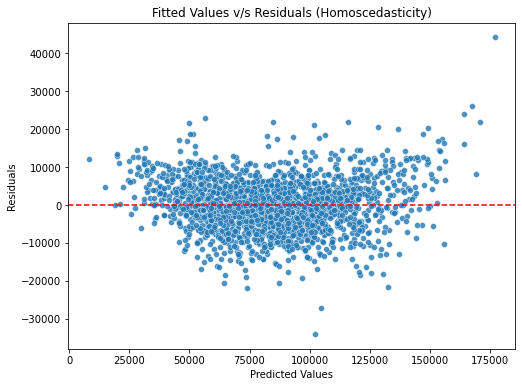

In [105]:
## c. Homoscedasticity

residuals = y_train - pred_y_train

plt.figure(figsize=(8,6))
sns.scatterplot(x=pred_y_train,y=residuals,alpha=0.8)
plt.axhline(0, color="red", linestyle="--") 
plt.title("Fitted Values v/s Residuals (Homoscedasticity)")
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.show()

In [106]:
# Run White's Test

from statsmodels.stats.diagnostic import het_breuschpagan,het_white

lm_stat, lm_pvalue, f_stat, f_pvalue = het_white(residuals, X_vif)

print(f"White's Test LM P-Value: {lm_pvalue:.4e}")
print(f"White's Test LM Stat-Value: {lm_stat:.4e}")

if lm_pvalue < 0.05:
    print("Reject H0: Heteroscedasticity is present.")
else:
    print("Fail to reject H0: Data is homoscedastic (constant variance).")

White's Test LM P-Value: 2.2526e-27
White's Test LM Stat-Value: 3.6389e+02
Reject H0: Heteroscedasticity is present.


In [107]:
# Run the Breusch-Pagan-Godfrey test
lm_stat, lm_pvalue, f_stat, f_pvalue = het_breuschpagan(residuals, X_vif)

print("--- Breusch-Pagan Test Results ---")
print(f"Lagrange Multiplier (LM) Statistic: {lm_stat:.4f}")
print(f"LM P-Value: {lm_pvalue:.4e}")
print(f"F-Statistic: {f_stat:.4f}")
print(f"F-Test P-Value: {f_pvalue:.4e}\n")

# 4. Interpret the Null Hypothesis (H0: Homoscedasticity / Constant Variance)
if lm_pvalue < 0.05:
    print("Reject H0: Heteroscedasticity is present (variance is not constant).")
else:
    print("Fail to reject H0: Data is homoscedastic (variance is constant).")

--- Breusch-Pagan Test Results ---
Lagrange Multiplier (LM) Statistic: 51.0133
LM P-Value: 8.2150e-06
F-Statistic: 3.4620
F-Test P-Value: 7.0170e-06

Reject H0: Heteroscedasticity is present (variance is not constant).


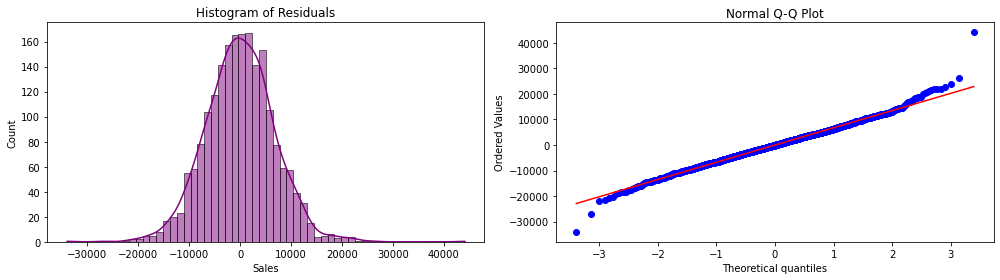

Goal: Residuals should look bell-curved, and Q-Q dots should line up flat against the red line.


In [102]:
## 2. NORMALITY OF RESIDUALS

from scipy.stats import probplot

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(residuals, kde=True, ax=axes[0], color='purple')
axes[0].set_title("Histogram of Residuals")

probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot")
plt.tight_layout()
plt.show()
print("Goal: Residuals should look bell-curved, and Q-Q dots should line up flat against the red line.")


In [103]:
## Run Shapiro test

from scipy.stats import shapiro

sh_stat, sh_p_value = shapiro(residuals)

print(sh_stat)
print(sh_p_value)

if sh_p_value < 0.05:
    print('Reject H0 : Residuals do not follow Normal Distribution curve')
else:
    print('Fail to Reject H0 : Residuals follow Normal Distribution curve')

0.9912986755371094
1.448819619831454e-09
Reject H0 : Residuals do not follow Normal Distribution curve


In [108]:
## 3. INDEPENDENCE OF ERRORS

from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

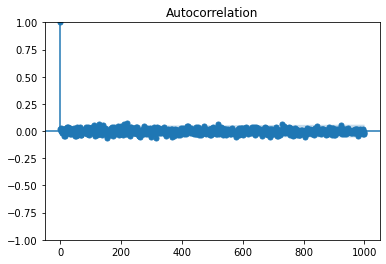

In [109]:
plot_acf(residuals,lags=1000)
plt.show()

In [110]:
## Durbin-Watson test

from statsmodels.stats.stattools import durbin_watson

durbin_watson(residuals)

1.954238870472294

### Insights: No Autocorrelation

In [111]:
## Check on testing dataset

pred_y_test = model.predict(X_test_scaled)
pred_y_test[:10]

array([124092.80436671,  91055.84425359,  55636.56684565,  96281.70666751,
        86334.57769814,  56252.6609788 ,  59391.43808575,  59513.54116376,
        81102.00807272,  60285.89343858])

In [112]:
rmse_test = np.sqrt(mean_squared_error(y_test,pred_y_test))
rmse_test

6607.1907576709345

In [113]:
## r2 score for Test Dataset

r2_test = r2_score(y_test,pred_y_test)
r2_test

0.9472706967678467

### 💡 Business Takeaways

1. **Conversion rate is the #1 driver of sales.** A 1-point rise in `Conversion_Rate` is linked to roughly **+35,900 Sales**, and a typical jump (one standard deviation) adds about 23,000, more than any marketing channel. Improving the checkout, landing pages and offers is likely to pay off more than simply buying more traffic.

2. **Every marketing channel helps, and Search looks most efficient.** Per 1 unit of spend, Search Engine Marketing adds about **2.1 Sales**, Social Media about **1.7** and TV about **1.3**. Discounts also help (about +505 Sales per extra discount point). If budget is tight, shifting some money from TV to Search and Social is worth testing.

3. **More visitors alone do not guarantee more sales.** After accounting for conversion rate and spend, `Website_Traffic` has almost no effect (coefficient ≈ 0). Category, region and customer segment matter only a little compared with the average sale of about 84,000.

**Model quality:** the model explains about **95% of the variation in Sales** on unseen test data (R² ≈ 0.95), with an average error of about 6,400 (RMSE). Train and Test scores are very close, so the model is **not overfitting**.

⚠️ **Remember:** regression shows *association*, not proof of cause and effect. Treat these results as strong hints and confirm them with small real-world experiments (A/B tests) before moving big budgets.

---

### Let's apply Lasso and Ridge

In [114]:
from sklearn.linear_model import Lasso, Ridge

In [126]:
model1 = Lasso(alpha = 0.000001)
model1

Lasso(alpha=1e-06)

In [127]:
model1.fit(X_train_scaled,y_train)

Lasso(alpha=1e-06)

In [128]:
model1.predict(X_train_scaled)

array([ 31408.18548753, 138522.83683108,  89557.96308107, ...,
        90682.83718829,  97251.24604533, 107617.84764422])

In [129]:
np.sqrt(mean_squared_error(y_train,model1.predict(X_train_scaled)))

6766.354982053156

In [130]:
r2_score(y_train,model1.predict(X_train_scaled))

0.9402522311632129

In [137]:
model2 = Ridge(alpha = 0.000001)
model2

Ridge(alpha=1e-06)

In [138]:
model2.fit(X_train_scaled,y_train)

Ridge(alpha=1e-06)

In [139]:
model2.predict(X_train_scaled)

array([ 31408.18552444, 138522.83680373,  89557.96307777, ...,
        90682.83717727,  97251.24605112, 107617.84763634])

In [140]:
np.sqrt(mean_squared_error(y_train,model2.predict(X_train_scaled)))

6766.354982053156

In [141]:
r2_score(y_train,model2.predict(X_train_scaled))

0.9402522311632129

In [150]:
alphass = [0.0001,0.001,0.01,0.1,1,10,100]

for alph in alphass:
    model1 = Lasso(alpha = alph)
    
    model1.fit(X_train_scaled,y_train)
    
    pred_y_ls_train = model1.predict(X_train_scaled)
    
    rmse_ls = np.sqrt(mean_squared_error(y_train,pred_y_ls_train))
    
    r2_ls = r2_score(y_train,pred_y_ls_train)
    
    print(f'Prredicted Values of Sales using Lasso for {alph} {pred_y_ls_train}')
    print('-'*50)
    print(f'RMSE using Lasso for {alph} {rmse_ls}')
    print('-'*50)
    print(f'R2_Score using Lasso for {alph} {r2_ls}')
    print(' '*100)

Prredicted Values of Sales using Lasso for 0.0001 [ 31408.18508815 138522.83680913  89557.9624003  ...  90682.83760119
  97251.24553235 107617.84701093]
--------------------------------------------------
RMSE using Lasso for 0.0001 6766.354982053261
--------------------------------------------------
R2_Score using Lasso for 0.0001 0.940252231163211
                                                                                                    
Prredicted Values of Sales using Lasso for 0.001 [ 31408.18145547 138522.83660886  89557.95616755 ...  90682.84132223
  97251.24083826 107617.84118472]
--------------------------------------------------
RMSE using Lasso for 0.001 6766.354982063679
--------------------------------------------------
R2_Score using Lasso for 0.001 0.940252231163027
                                                                                                    
Prredicted Values of Sales using Lasso for 0.01 [ 31408.14516441 138522.83461426  89557.89444579 ..

In [151]:
alphass = np.logspace(-5,4,10)

for alph in alphass:
    model1 = Lasso(alpha = alph)
    
    model1.fit(X_train_scaled,y_train)
    
    pred_y_ls_train = model1.predict(X_train_scaled)
    
    rmse_ls = np.sqrt(mean_squared_error(y_train,pred_y_ls_train))
    
    r2_ls = r2_score(y_train,pred_y_ls_train)
    
    print(f'Prredicted Values of Sales using Lasso for {alph} {pred_y_ls_train}')
    print('-'*50)
    print(f'RMSE using Lasso for {alph} {rmse_ls}')
    print('-'*50)
    print(f'R2_Score using Lasso for {alph} {r2_ls}')
    print(' '*100)

Prredicted Values of Sales using Lasso for 1e-05 [ 31408.18545119 138522.83682908  89557.96301859 ...  90682.83722538
  97251.24599828 107617.84758572]
--------------------------------------------------
RMSE using Lasso for 1e-05 6766.354982053157
--------------------------------------------------
R2_Score using Lasso for 1e-05 0.9402522311632129
                                                                                                    
Prredicted Values of Sales using Lasso for 0.0001 [ 31408.18508815 138522.83680913  89557.9624003  ...  90682.83760119
  97251.24553235 107617.84701093]
--------------------------------------------------
RMSE using Lasso for 0.0001 6766.354982053261
--------------------------------------------------
R2_Score using Lasso for 0.0001 0.940252231163211
                                                                                                    
Prredicted Values of Sales using Lasso for 0.001 [ 31408.18145547 138522.83660886  89557.95616755 